# 07 — Auditoria e insights de tráfego do acesso terrestre ao Porto de Santos

**Fontes separadas:** volume pedagiado horário e volume de tráfego diário, lote L22. **Nunca somar essas fontes.**

**Alerta importante:** O CSV diário disponibilizado apresenta somente os dias 1 a 12 de cada mês dos anos completos. Isso indica provável erro na conversão de datas de origem. Portanto, análises temporais da base diária estão **suspensas** até corrigir o ETL a partir dos arquivos brutos. Além disso, parte das datas de 2026 está no futuro em relação a 05/11/2026; foram segregadas para revisão.

Os valores das categorias de veículos nem sempre fecham com o total informado na base horária; não substituir automaticamente o total.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
while ROOT.name != 'porto-santos':
    if ROOT == ROOT.parent: raise FileNotFoundError('Abra o notebook dentro de porto-santos')
    ROOT = ROOT.parent
BASE = ROOT / 'data' / 'processed' / 'trafego'
REP = ROOT / 'reports' / 'trafego'
import json
with (REP / 'auditoria_trafego_final.json').open(encoding='utf-8') as f: auditoria=json.load(f)
print(json.dumps(auditoria,indent=2,ensure_ascii=False))

{
  "diario": {
    "contagens": {
      "linhas_lidas": 66016,
      "datas_invalidas": 0,
      "datas_futuras": 928,
      "ano_divergente": 0,
      "volumes_invalidos": 0,
      "diferenca_classes": 0
    },
    "resultado": {
      "agregadas": 17049,
      "dias_praca_sentido": 5706,
      "datas": 815,
      "primeira": "2021-01-01",
      "ultima": "2026-11-05",
      "pracas": [
        "BATISTINI",
        "DIADEMA",
        "ELDORADO",
        "PIRATININGA",
        "RIACHO GRANDE",
        "SANTOS",
        "SÃO VICENTE"
      ]
    }
  },
  "horario": {
    "contagens": {
      "linhas_lidas": 1878845,
      "datas_invalidas": 0,
      "datas_futuras": 7040,
      "ano_divergente": 0,
      "volumes_invalidos": 0,
      "diferenca_classes": 178959
    },
    "resultado": {
      "agregadas": 538136,
      "dias_praca_sentido": 9712,
      "datas": 1713,
      "primeira": "2021-01-01",
      "ultima": "2026-11-05",
      "pracas": [
        "BATISTINI",
        "DIADEMA",


## 1. Importar bases analíticas e verificar cobertura

In [2]:
h = pd.read_csv(BASE/'trafego_horario_analitico_2021_2026.csv', parse_dates=['DATA'])
d = pd.read_csv(BASE/'trafego_diario_analitico_2021_2026.csv', parse_dates=['DATA'])
print('Linhas agregadas: horário',len(h),'| diário',len(d))
for nome,x in [('horario',h),('diario',d)]:
    print('\n',nome)
    display(x.groupby('ANO').agg(dias_observados=('DATA','nunique'), registros_agregados=('DATA','size')))
    display(x[['DATA','PRACA','SENTIDO','TOTAL_VEICULOS_INFORMADOS']].head())

Linhas agregadas: horário 538136 | diário 17049

 horario


,dias_observados,registros_agregados
ANO,,
2021,342,91218
2022,344,86107
2023,314,110916
2024,266,96221
2025,258,78327
2026,189,75347


,DATA,PRACA,SENTIDO,TOTAL_VEICULOS_INFORMADOS
0,2021-01-01,BATISTINI,SUL,1
1,2021-01-01,BATISTINI,SUL,1
2,2021-01-01,BATISTINI,SUL,1
3,2021-01-01,BATISTINI,SUL,1
4,2021-01-01,BATISTINI,SUL,1



 diario


,dias_observados,registros_agregados
ANO,,
2021,144,2984
2022,144,3010
2023,144,3016
2024,144,3021
2025,144,3023
2026,95,1995


,DATA,PRACA,SENTIDO,TOTAL_VEICULOS_INFORMADOS
0,2021-01-01,BATISTINI,SUL,5
1,2021-01-01,BATISTINI,SUL,33
2,2021-01-01,BATISTINI,SUL,2478
3,2021-01-01,DIADEMA,SUL,3
4,2021-01-01,DIADEMA,SUL,24


In [4]:
df_diario = pd.read_csv(
    ROOT / "data" / "processed" / "trafego" / "volume_trafego_acesso_diario.csv"
)

df_diario["DATA"] = pd.to_datetime(
    df_diario["DATA"],
    format="%Y-%m-%d",
    errors="coerce"
)

print("Datas inválidas:", df_diario["DATA"].isna().sum())

print("\nDias encontrados:")
print(sorted(df_diario["DATA"].dt.day.dropna().unique()))

print("\nQuantidade por ano:")
display(df_diario.groupby(df_diario["DATA"].dt.year).size())

Datas inválidas: 0

Dias encontrados:
[np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13), np.int32(14), np.int32(15), np.int32(16), np.int32(17), np.int32(18), np.int32(19), np.int32(20), np.int32(21), np.int32(22), np.int32(23), np.int32(24), np.int32(25), np.int32(26), np.int32(27), np.int32(28), np.int32(29), np.int32(30), np.int32(31)]

Quantidade por ano:


DATA
2021    29137
2022    29842
2023    30274
2024    29755
2025    28285
2026    20130
dtype: int64

In [6]:
# Validação final das datas e cobertura temporal

import pandas as pd

data_limite = pd.Timestamp("2026-11-05")

print("Datas posteriores à data atual:")
print((df_diario["DATA"] > data_limite).sum())

print("\nPeríodo por ano:")
display(
    df_diario.groupby(df_diario["DATA"].dt.year)
    .agg(
        primeira_data=("DATA", "min"),
        ultima_data=("DATA", "max"),
        registros=("DATA", "size"),
        dias_distintos=("DATA", "nunique")
    )
)

print("\nMeses disponíveis por ano:")
display(
    pd.crosstab(
        df_diario["DATA"].dt.year,
        df_diario["DATA"].dt.month
    )
)

Datas posteriores à data atual:
0

Período por ano:


,primeira_data,ultima_data,registros,dias_distintos
DATA,,,,
2021,2021-01-01,2021-12-31,29137,365
2022,2022-01-01,2022-12-31,29842,365
2023,2023-01-01,2023-12-31,30274,365
2024,2024-01-01,2024-12-31,29755,366
2025,2025-01-01,2025-12-31,28285,365
2026,2026-01-01,2026-09-30,20130,273



Meses disponíveis por ano:


DATA,1,2,3,4,5,6,7,8,9,10,11,12
DATA,,,,,,,,,,,,
2021,2443,2225,2455,2360,2478,2392,2483,2466,2423,2472,2430,2510
2022,2486,2258,2522,2429,2511,2402,2526,2518,2458,2580,2528,2624
2023,2553,2310,2592,2460,2580,2462,2600,2559,2485,2565,2518,2590
2024,2572,2419,2580,2509,2585,2519,2594,2627,2549,2590,1621,2590
2025,2491,1928,2142,2077,2153,2152,2492,2580,2526,2606,2483,2655
2026,2666,2432,2684,2768,1730,2709,1733,1729,1679,0,0,0


In [13]:
# Cobertura de registros por praça e mês

base = df_diario.copy()

base["DATA"] = pd.to_datetime(
    base["DATA"],
    format="%Y-%m-%d",
    errors="coerce"
)

base["ANO"] = base["DATA"].dt.year
base["MES"] = base["DATA"].dt.month

cobertura_pracas = (
    base.groupby(["ANO", "MES", "PRACA"])
    .agg(
        registros=("DATA", "size"),
        dias_com_registro=("DATA", "nunique")
    )
    .reset_index()
)

# Quantos dias existem em cada mês?
cobertura_pracas["dias_esperados"] = pd.to_datetime(
    dict(
        year=cobertura_pracas["ANO"],
        month=cobertura_pracas["MES"],
        day=1
    )
).dt.days_in_month

cobertura_pracas["cobertura_dias_pct"] = (
    cobertura_pracas["dias_com_registro"]
    / cobertura_pracas["dias_esperados"]
    * 100
).round(2)

# Identificar meses com cobertura incompleta
alertas_cobertura = cobertura_pracas[
    cobertura_pracas["cobertura_dias_pct"] < 90
].sort_values(["ANO", "MES", "PRACA"])

print("Meses/praças com cobertura inferior a 90%:")
display(alertas_cobertura)

print("\nResumo de cobertura por praça:")
display(
    cobertura_pracas.groupby("PRACA")["cobertura_dias_pct"]
    .agg(["min", "mean", "max"])
    .round(2)
)

Meses/praças com cobertura inferior a 90%:


,ANO,MES,PRACA,registros,dias_com_registro,dias_esperados,cobertura_dias_pct



Resumo de cobertura por praça:


,min,mean,max
PRACA,,,
BATISTINI,100.0,100.0,100.0
DIADEMA,100.0,100.0,100.0
ELDORADO,100.0,100.0,100.0
PIRATININGA,100.0,100.0,100.0
RIACHO GRANDE,100.0,100.0,100.0
SANTOS,100.0,100.0,100.0
SÃO VICENTE,100.0,100.0,100.0


In [14]:
# Volume diário de veículos por praça e sentido

coluna_volume = "TOTAL_VEICULOS_INFORMADOS"

base[coluna_volume] = pd.to_numeric(
    base[coluna_volume],
    errors="coerce"
)

trafego_diario = (
    base.groupby(
        ["DATA", "PRACA", "SENTIDO"],
        dropna=False
    )
    .agg(
        volume_veiculos=(
            coluna_volume,
            lambda x: x.sum(min_count=1)
        ),
        registros=("DATA", "size"),
        medicoes_validas=(coluna_volume, "count")
    )
    .reset_index()
)

trafego_diario["ANO"] = trafego_diario["DATA"].dt.year
trafego_diario["MES"] = trafego_diario["DATA"].dt.month

display(trafego_diario.head(10))

,DATA,PRACA,SENTIDO,volume_veiculos,registros,medicoes_validas,ANO,MES
0,2021-01-01,BATISTINI,SUL,2516,11,11,2021,1
1,2021-01-01,DIADEMA,SUL,6074,9,9,2021,1
2,2021-01-01,ELDORADO,SUL,2767,7,7,2021,1
3,2021-01-01,PIRATININGA,SUL,30066,11,11,2021,1
4,2021-01-01,RIACHO GRANDE,SUL,6968,10,10,2021,1
5,2021-01-01,SANTOS,OESTE,11661,11,11,2021,1
6,2021-01-01,SÃO VICENTE,LESTE,21906,12,12,2021,1
7,2021-01-02,BATISTINI,SUL,2794,9,9,2021,1
8,2021-01-02,DIADEMA,SUL,7823,10,10,2021,1
9,2021-01-02,ELDORADO,SUL,3281,10,10,2021,1


In [15]:
from pathlib import Path

# Localizar a raiz do projeto
ROOT = Path.cwd().resolve()

while ROOT.name != "porto-santos":
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Raiz do projeto não encontrada.")
    ROOT = ROOT.parent

DESTINO = ROOT / "data" / "processed" / "trafego"
DESTINO.mkdir(parents=True, exist_ok=True)

# Exportar volume diário
trafego_diario.to_csv(
    DESTINO / "trafego_acesso_resumo_diario.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar qualidade mensal por praça
cobertura_pracas.to_csv(
    DESTINO / "trafego_acesso_cobertura_mensal.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar alertas de cobertura
alertas_cobertura.to_csv(
    DESTINO / "trafego_acesso_alertas_cobertura.csv",
    index=False,
    encoding="utf-8-sig"
)

print("CSVs exportados com sucesso!")
print("Pasta:", DESTINO)

CSVs exportados com sucesso!
Pasta: C:\Users\Lenovo\Desktop\porto-santos\data\processed\trafego


## 2. Teste automático de integridade temporal

O indicador `apto_analise_temporal` deve ser **falso** quando a origem apresentar padrão suspeito de datas. Não calcular tendência mensal da base diária enquanto não corrigir a origem.

In [7]:
presenca_dias = (d.assign(dia=d.DATA.dt.day)
                   .groupby(['ANO','dia']).size().unstack(fill_value=0))
display(presenca_dias)
anos_completos = [a for a in sorted(d.ANO.unique()) if a < 2026]
dias_maiores_12 = int(d.loc[(d.ANO.isin(anos_completos)) & (d.DATA.dt.day>12)].shape[0])
apto_analise_temporal_diario = dias_maiores_12 > 0
print('Base diária apta a tendências?',apto_analise_temporal_diario)
if not apto_analise_temporal_diario:
    print('BLOQUEADO: série diária apresenta somente dias 1 a 12. Corrija a origem antes de analisar sazonalidade.')

dia,1,2,3,4,5,6,7,8,9,10,11,12
ANO,,,,,,,,,,,,
2021,249,247,246,247,249,249,248,249,249,250,250,251
2022,250,252,251,251,251,250,251,249,251,251,252,251
2023,251,252,251,251,251,252,251,251,251,251,252,252
2024,251,251,252,252,252,252,252,252,252,252,251,252
2025,252,252,252,252,251,252,252,252,252,252,252,252
2026,231,231,231,231,231,210,210,210,210,0,0,0


Base diária apta a tendências? False
BLOQUEADO: série diária apresenta somente dias 1 a 12. Corrija a origem antes de analisar sazonalidade.


## 3. Distribuição por praça e sentido (fonte horária)

Valores representam passagens registradas; não equivalem a caminhões com destino ao porto.

,PRACA,TOTAL_VEICULOS_INFORMADOS
3,PIRATININGA,57501085
5,SANTOS,27043735
1,DIADEMA,23555921
6,SÃO VICENTE,23487637
4,RIACHO GRANDE,19486605
0,BATISTINI,17583882
2,ELDORADO,11281855


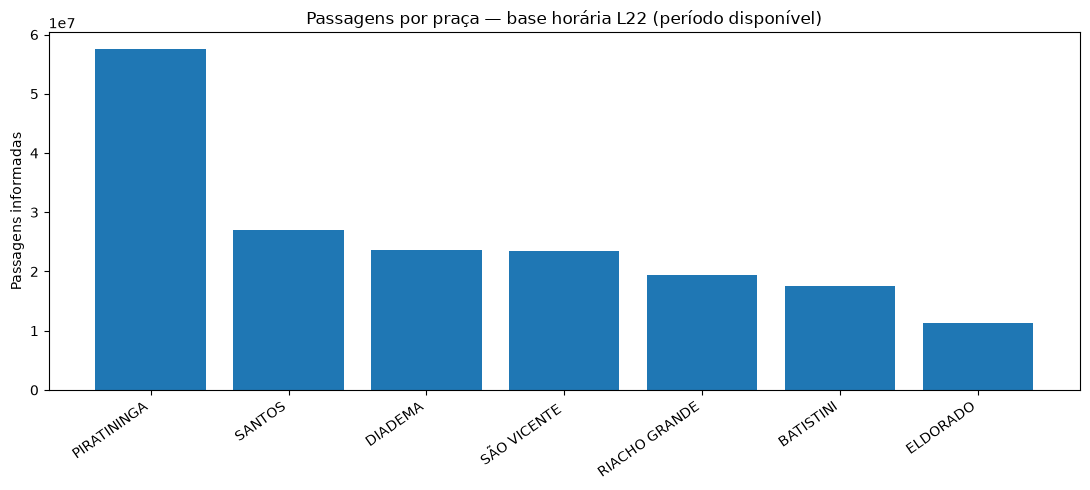

In [8]:
p = (h.groupby('PRACA',as_index=False)['TOTAL_VEICULOS_INFORMADOS']
     .sum().sort_values('TOTAL_VEICULOS_INFORMADOS',ascending=False))
display(p)
plt.figure(figsize=(11,5))
plt.bar(p.PRACA,p.TOTAL_VEICULOS_INFORMADOS)
plt.xticks(rotation=35,ha='right');plt.ylabel('Passagens informadas')
plt.title('Passagens por praça — base horária L22 (período disponível)')
plt.tight_layout();plt.show()

## 4. Tipos de passagem e veículos pesados (fonte horária)

In [9]:
tipos=(h.groupby('TIPO_PASSAGEM',dropna=False,as_index=False)
        [['TOTAL_VEICULOS_INFORMADOS','VEICULOS_PESADOS_INFORMADOS']].sum())
display(tipos)
pesados_por_praca=(h.groupby('PRACA',as_index=False)
                  [['VEICULOS_PESADOS_INFORMADOS','TOTAL_VEICULOS_INFORMADOS']].sum())
pesados_por_praca['percentual_pesados_sobre_total']=(100*pesados_por_praca.VEICULOS_PESADOS_INFORMADOS/pesados_por_praca.TOTAL_VEICULOS_INFORMADOS).round(2)
display(pesados_por_praca.sort_values('percentual_pesados_sobre_total',ascending=False))

,TIPO_PASSAGEM,TOTAL_VEICULOS_INFORMADOS,VEICULOS_PESADOS_INFORMADOS
0,EVASÃO,263394,82963
1,ISENTAS,1120646,88369
2,VALIDAS,178556680,27986155


,PRACA,VEICULOS_PESADOS_INFORMADOS,TOTAL_VEICULOS_INFORMADOS,percentual_pesados_sobre_total
4,RIACHO GRANDE,6709411,19486605,34.43
5,SANTOS,8453165,27043735,31.26
0,BATISTINI,2968783,17583882,16.88
6,SÃO VICENTE,2577694,23487637,10.97
3,PIRATININGA,5887543,57501085,10.24
2,ELDORADO,703257,11281855,6.23
1,DIADEMA,857634,23555921,3.64


## 5. Distribuição horária — fonte horária

O indicador é o total observado ao longo dos dias disponíveis; não comparar horas sem avaliar cobertura por data.

,HORA,TOTAL_VEICULOS_INFORMADOS
0,0,2591524
1,1,1750602
2,2,1299474
3,3,1220964
4,4,1762290
5,5,3521386
6,6,7182750
7,7,9443371
8,8,9684375
9,9,9977618


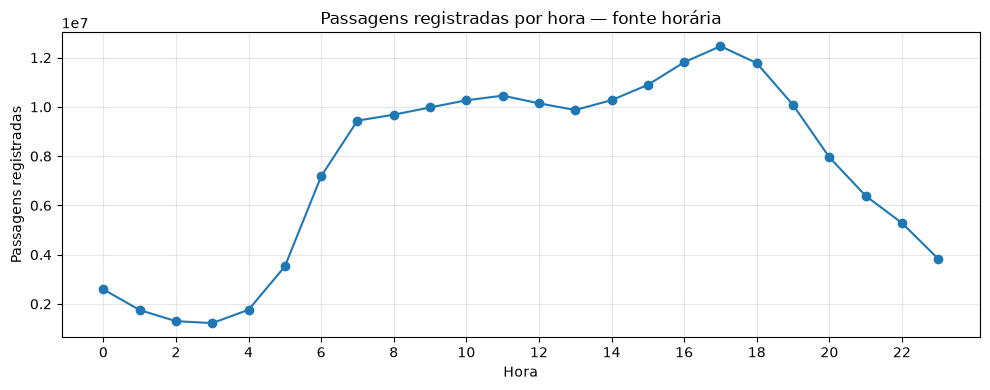

In [10]:
hora=(h.groupby('HORA',as_index=False)['TOTAL_VEICULOS_INFORMADOS'].sum()
      .sort_values('HORA'))
display(hora)
plt.figure(figsize=(10,4))
plt.plot(hora.HORA,hora.TOTAL_VEICULOS_INFORMADOS,marker='o')
plt.title('Passagens registradas por hora — fonte horária')
plt.xlabel('Hora');plt.ylabel('Passagens registradas');plt.xticks(range(0,24,2));plt.grid(alpha=.3)
plt.tight_layout();plt.show()

## 6. Série temporal — somente após validação

As datas do CSV horário também têm cobertura irregular, e a fonte diária está bloqueada. Visualização exploratória, nunca inferir causalidade nem tendências comparáveis sem revisar os arquivos de origem.

In [11]:
if apto_analise_temporal_diario:
    v = pd.read_csv(BASE/'trafego_diario_resumo_mensal.csv')
    display(v.head())
else:
    print('Análise temporal da fonte diária não executada: datas de origem precisam ser corrigidas.')

Análise temporal da fonte diária não executada: datas de origem precisam ser corrigidas.


## 7. Tabelas para Power BI

Os principais CSVs foram criados pelo script `clean_trafego_final.py`. Use o arquivo horário analítico para gráficos de praça, sentido, hora e tipo de passagem. **Não use a série mensal da fonte diária até corrigir as datas**.

In [12]:
for arquivo in sorted(BASE.glob('trafego_*.csv')):
    print(arquivo.name, '—',f'{arquivo.stat().st_size/1024**2:.1f} MB')
print('Auditoria:', REP/'auditoria_trafego_final.json')

trafego_diario_analitico_2021_2026.csv — 1.0 MB
trafego_diario_resumo_diario.csv — 0.3 MB
trafego_diario_resumo_mensal.csv — 0.0 MB
trafego_horario_analitico_2021_2026.csv — 31.1 MB
trafego_horario_resumo_diario.csv — 0.5 MB
trafego_horario_resumo_mensal.csv — 0.0 MB
trafego_serie_mensal_powerbi.csv — 0.0 MB
Auditoria: C:\Users\Lenovo\Desktop\porto-santos\reports\trafego\auditoria_trafego_final.json
